In [1]:
from pathlib import Path
import gzip
import hashlib
import json
import platform
import struct
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists() and (p / "notebooks").is_dir())
RAW = ROOT / "data" / "raw"
SPLITS = ROOT / "data" / "splits"
RESULTS = ROOT / "results" / "exploration"
for folder in (RAW, SPLITS, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
CLASS_NAMES = np.array(["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"])
SOURCE_COMMIT = "b2617bb6d3ffa2e429640350f613e3291e10b141"
SOURCE_URL = f"https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/{SOURCE_COMMIT}/data/fashion"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
environment = {"python": platform.python_version(), **{name: version(name) for name in ("numpy", "pandas", "matplotlib", "scikit-learn", "requests")}}
display(pd.Series(environment, name="Version"))

python          3.12.0
numpy            2.5.4
pandas           3.0.6
matplotlib      3.11.2
scikit-learn     1.9.1
requests        2.34.2
Name: Version, dtype: str

In [2]:
EXPECTED_MD5 = {
    "train-images-idx3-ubyte.gz": "8d4fb7e6c68d591d4c3dfef9ec88bf0d",
    "train-labels-idx1-ubyte.gz": "25c81989df183df01b3e8a0aad5dffbe",
    "t10k-images-idx3-ubyte.gz": "bef4ecab320f06d8554ea6380940ec79",
    "t10k-labels-idx1-ubyte.gz": "bb300cfdad3c16e7a12a480ee83cd310",
}
manifest = []
for filename, expected in EXPECTED_MD5.items():
    path = RAW / filename
    if not path.exists():
        response = requests.get(f"{SOURCE_URL}/{filename}", timeout=(15, 120))
        response.raise_for_status()
        payload = response.content
        if hashlib.md5(payload).hexdigest() != expected:
            raise ValueError(f"Download checksum mismatch: {filename}")
        path.write_bytes(payload)
    payload = path.read_bytes()
    if hashlib.md5(payload).hexdigest() != expected:
        raise ValueError(f"Cached file checksum mismatch: {filename}")
    manifest.append({"filename": filename, "bytes": len(payload), "md5_verified": True,
                     "sha256": hashlib.sha256(payload).hexdigest(), "source": f"{SOURCE_URL}/{filename}"})
display(pd.DataFrame(manifest)[["filename", "bytes", "md5_verified"]])

,filename,bytes,md5_verified
0,train-images-idx3-ubyte.gz,26421880,True
1,train-labels-idx1-ubyte.gz,29515,True
2,t10k-images-idx3-ubyte.gz,4422102,True
3,t10k-labels-idx1-ubyte.gz,5148,True


In [3]:
def read_idx(path):
    with gzip.open(path, "rb") as stream:
        payload = stream.read()
    zero_a, zero_b, dtype_code, dimensions = struct.unpack(">BBBB", payload[:4])
    if (zero_a, zero_b, dtype_code) != (0, 0, 8) or dimensions not in (1, 3):
        raise ValueError(f"Invalid IDX header: {path.name}")
    offset = 4 + 4 * dimensions
    shape = struct.unpack(">" + "I" * dimensions, payload[4:offset])
    values = np.frombuffer(payload, dtype=np.uint8, offset=offset)
    if values.size != np.prod(shape):
        raise ValueError(f"Invalid IDX payload size: {path.name}")
    return values.reshape(shape)

images = read_idx(RAW / "train-images-idx3-ubyte.gz")
labels = read_idx(RAW / "train-labels-idx1-ubyte.gz")
test_images = read_idx(RAW / "t10k-images-idx3-ubyte.gz")
test_labels = read_idx(RAW / "t10k-labels-idx1-ubyte.gz")
assert images.shape == (60000, 28, 28) and labels.shape == (60000,)
assert test_images.shape == (10000, 28, 28) and test_labels.shape == (10000,)
quality = []
for name, x, y in [("Official training", images, labels), ("Official test (integrity only)", test_images, test_labels)]:
    assert np.isfinite(x).all() and np.isfinite(y).all()
    assert np.isin(y, np.arange(10)).all()
    quality.append({"dataset": name, "images": len(x), "image_shape": str(x.shape[1:]),
                    "dtype": str(x.dtype), "missing_pixels": int(np.isnan(x).sum()),
                    "missing_labels": int(np.isnan(y).sum()), "invalid_labels": int((~np.isin(y, np.arange(10))).sum()),
                    "pixel_min": int(x.min()), "pixel_max": int(x.max())})
display(pd.DataFrame(quality))

,dataset,images,image_shape,dtype,missing_pixels,missing_labels,invalid_labels,pixel_min,pixel_max
0,Official training,60000,"(28, 28)",uint8,0,0,0,0,255
1,Official test (integrity only),10000,"(28, 28)",uint8,0,0,0,0,255


In [4]:
training_hashes = np.array([hashlib.sha256(image.tobytes()).hexdigest() for image in images])
test_hashes = np.array([hashlib.sha256(image.tobytes()).hexdigest() for image in test_images])
unique_hashes, groups, group_counts = np.unique(training_hashes, return_inverse=True, return_counts=True)
duplicate_rows = pd.DataFrame({"group": groups, "label": labels}).groupby("group").agg(rows=("label", "size"), label_count=("label", "nunique"))
overlap_hashes = np.intersect1d(training_hashes, test_hashes)
audit = {
    "training_duplicate_groups": int((group_counts > 1).sum()),
    "training_rows_in_duplicate_groups": int(group_counts[group_counts > 1].sum()),
    "training_extra_duplicate_rows": int((group_counts - 1).sum()),
    "training_groups_with_conflicting_labels": int((duplicate_rows.label_count > 1).sum()),
    "test_extra_duplicate_rows": int(len(test_hashes) - len(np.unique(test_hashes))),
    "train_test_shared_exact_images": int(len(overlap_hashes)),
    "test_rows_matching_official_training": int(np.isin(test_hashes, training_hashes).sum()),
}
display(pd.Series(audit, name="Count"))

training_duplicate_groups                  0
training_rows_in_duplicate_groups          0
training_extra_duplicate_rows              0
training_groups_with_conflicting_labels    0
test_extra_duplicate_rows                  0
train_test_shared_exact_images             0
test_rows_matching_official_training       0
Name: Count, dtype: int64

In [5]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_indices, validation_indices = next(splitter.split(np.zeros(len(labels)), labels, groups))
assert np.intersect1d(train_indices, validation_indices).size == 0
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(len(labels)))
assert np.intersect1d(groups[train_indices], groups[validation_indices]).size == 0
assert set(labels[train_indices]) == set(labels[validation_indices]) == set(range(10))
split_counts = pd.DataFrame({
    "class": CLASS_NAMES,
    "official_training": np.bincount(labels, minlength=10),
    "training": np.bincount(labels[train_indices], minlength=10),
    "validation": np.bincount(labels[validation_indices], minlength=10),
})
split_counts["validation_percent_within_class"] = (100 * split_counts.validation / split_counts.official_training).round(2)
display(split_counts)
print({"training": len(train_indices), "validation": len(validation_indices), "reserved_test": len(test_labels), "train_validation_duplicate_overlap": 0})

,class,official_training,training,validation,validation_percent_within_class
0,T-shirt/top,6000,4800,1200,20.0
1,Trouser,6000,4800,1200,20.0
2,Pullover,6000,4800,1200,20.0
3,Dress,6000,4800,1200,20.0
4,Coat,6000,4800,1200,20.0
5,Sandal,6000,4800,1200,20.0
6,Shirt,6000,4800,1200,20.0
7,Sneaker,6000,4800,1200,20.0
8,Bag,6000,4800,1200,20.0
9,Ankle boot,6000,4800,1200,20.0


{'training': 48000, 'validation': 12000, 'reserved_test': 10000, 'train_validation_duplicate_overlap': 0}


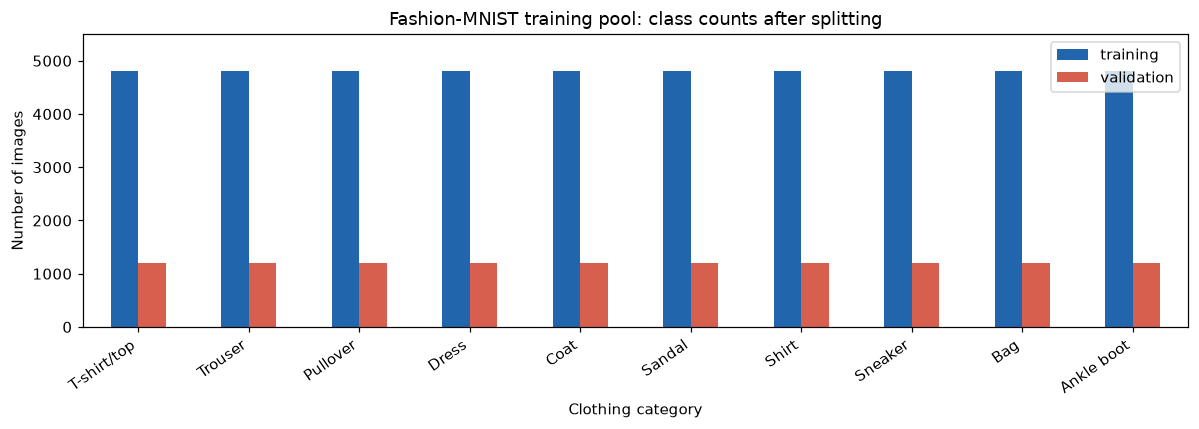

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
split_counts.set_index("class")[["training", "validation"]].plot.bar(ax=ax, color=["#2166ac", "#d6604d"])
ax.set(title="Fashion-MNIST training pool: class counts after splitting", xlabel="Clothing category", ylabel="Number of images", ylim=(0, 5500))
ax.tick_params(axis="x", rotation=35)
plt.setp(ax.get_xticklabels(), ha="right")
fig.tight_layout()
fig.savefig(RESULTS / "class-balance.png", bbox_inches="tight")
plt.show()

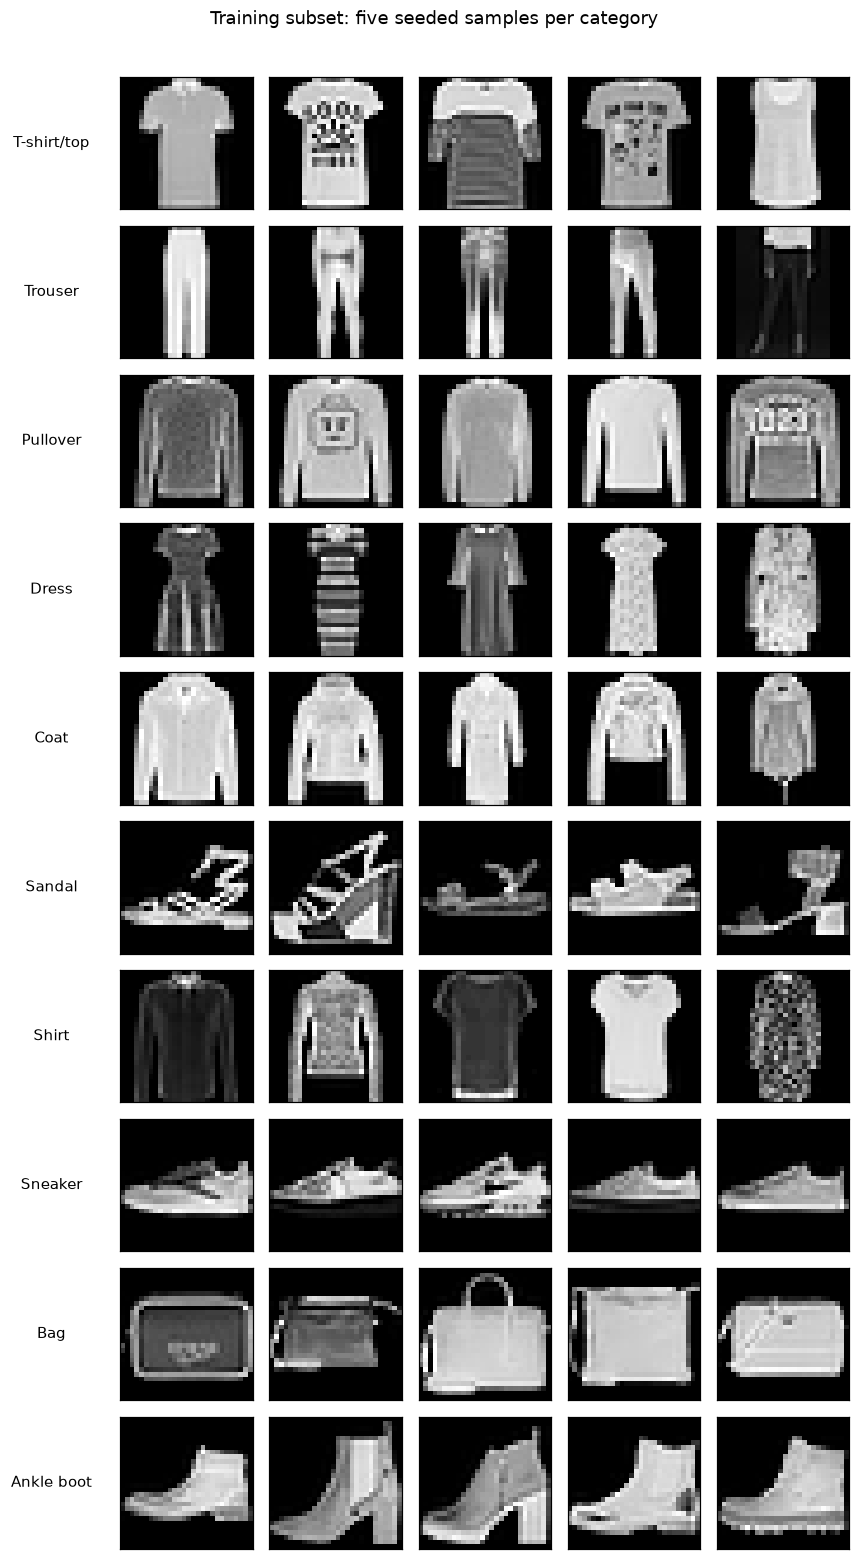

In [7]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(10, 5, figsize=(8, 14))
for class_id, row in enumerate(axes):
    candidates = train_indices[labels[train_indices] == class_id]
    selected = rng.choice(candidates, size=5, replace=False)
    for ax, index in zip(row, selected):
        ax.imshow(images[index], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([])
        ax.set_yticks([])
    row[0].set_ylabel(CLASS_NAMES[class_id], rotation=0, labelpad=45, va="center")
fig.suptitle("Training subset: five seeded samples per category", y=1.01)
fig.tight_layout()
fig.savefig(RESULTS / "training-samples.png", bbox_inches="tight")
plt.show()

all_black_training_images     0.00
constant_training_images      0.00
zero_pixel_percent           50.19
mean_pixel_intensity         72.93
Name: Value, dtype: float64

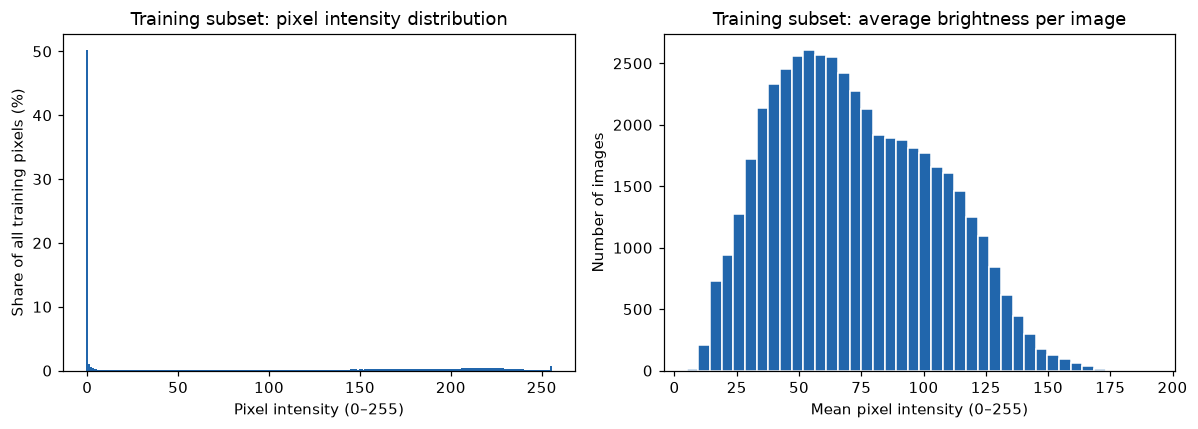

In [8]:
training_pixels = images[train_indices]
pixel_counts = np.bincount(training_pixels.ravel(), minlength=256)
image_means = training_pixels.mean(axis=(1, 2))
image_stds = training_pixels.std(axis=(1, 2))
image_quality = {
    "all_black_training_images": int((training_pixels.max(axis=(1, 2)) == 0).sum()),
    "constant_training_images": int((image_stds == 0).sum()),
    "zero_pixel_percent": round(float(100 * pixel_counts[0] / training_pixels.size), 2),
    "mean_pixel_intensity": round(float(training_pixels.mean()), 2),
}
display(pd.Series(image_quality, name="Value"))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(np.arange(256), 100 * pixel_counts / pixel_counts.sum(), width=1, color="#2166ac")
axes[0].set(title="Training subset: pixel intensity distribution", xlabel="Pixel intensity (0–255)", ylabel="Share of all training pixels (%)")
axes[1].hist(image_means, bins=40, color="#2166ac", edgecolor="white")
axes[1].set(title="Training subset: average brightness per image", xlabel="Mean pixel intensity (0–255)", ylabel="Number of images")
fig.tight_layout()
fig.savefig(RESULTS / "pixel-distributions.png", bbox_inches="tight")
plt.show()

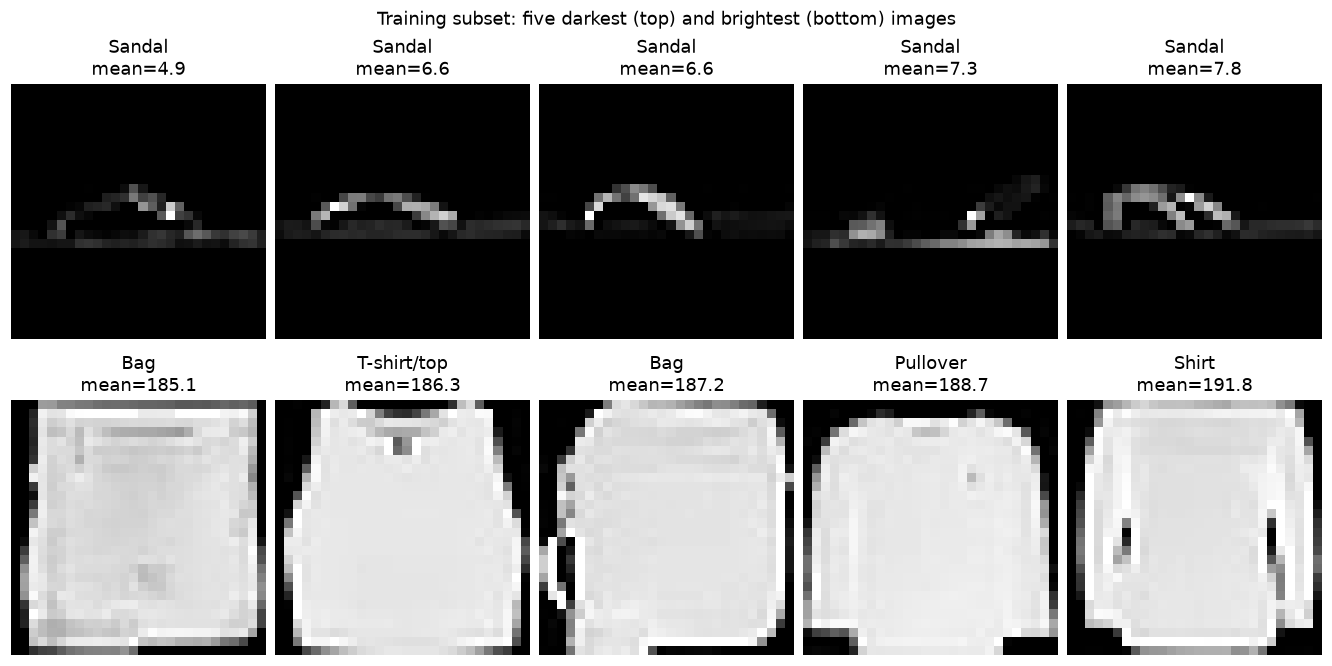

In [9]:
extreme_positions = np.concatenate([np.argsort(image_means)[:5], np.argsort(image_means)[-5:]])
fig, axes = plt.subplots(2, 5, figsize=(12, 6), layout="constrained")
for ax, position in zip(axes.ravel(), extreme_positions):
    index = train_indices[position]
    ax.imshow(images[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{CLASS_NAMES[labels[index]]}\nmean={image_means[position]:.1f}")
    ax.axis("off")
fig.suptitle("Training subset: five darkest (top) and brightest (bottom) images")
fig.savefig(RESULTS / "brightness-extremes.png", bbox_inches="tight")
plt.show()

In [10]:
X_train = images[train_indices].astype(np.float32) / 255.0
X_validation = images[validation_indices].astype(np.float32) / 255.0
y_train = labels[train_indices]
y_validation = labels[validation_indices]
X_train_flat = X_train.reshape(len(X_train), -1)
X_validation_flat = X_validation.reshape(len(X_validation), -1)
X_train_cnn = X_train[..., np.newaxis]
X_validation_cnn = X_validation[..., np.newaxis]
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_validation.min() <= X_validation.max() <= 1
assert np.array_equal(X_train_flat.reshape(X_train.shape), X_train)
display(pd.DataFrame([
    {"representation": "classical", "training_shape": str(X_train_flat.shape), "validation_shape": str(X_validation_flat.shape)},
    {"representation": "CNN (channels last)", "training_shape": str(X_train_cnn.shape), "validation_shape": str(X_validation_cnn.shape)},
]))

,representation,training_shape,validation_shape
0,classical,"(48000, 784)","(12000, 784)"
1,CNN (channels last),"(48000, 28, 28, 1)","(12000, 28, 28, 1)"


In [11]:
split_path = SPLITS / "train-validation-v1.npz"
if split_path.exists():
    with np.load(split_path, allow_pickle=False) as saved:
        assert np.array_equal(saved["train_indices"], train_indices), "Existing training split differs"
        assert np.array_equal(saved["validation_indices"], validation_indices), "Existing validation split differs"
else:
    np.savez_compressed(split_path, train_indices=train_indices, validation_indices=validation_indices)
metadata = {
    "source_commit": SOURCE_COMMIT,
    "seed": SEED,
    "splitter": "StratifiedGroupKFold",
    "n_splits": 5,
    "selected_fold": 0,
    "group_definition": "SHA256 of original uint8 image pixels; exact duplicates only",
    "training_count": len(train_indices),
    "validation_count": len(validation_indices),
    "test_count": len(test_images),
    "test_usage": "File integrity and exact-duplicate overlap audit only; no model selection or performance evaluation",
    "test_overlap_policy": "Preserve the official test set; report overlap and an overlap-free sensitivity result at final evaluation",
    "normalization": "float32 pixels divided by 255",
    "split_file_sha256": hashlib.sha256(split_path.read_bytes()).hexdigest(),
    "environment": environment,
    "files": manifest,
    "duplicate_audit": audit,
}
(SPLITS / "train-validation-v1.json").write_text(json.dumps(metadata, indent=2) + "\n")
(RESULTS / "quality-summary.json").write_text(json.dumps({"file_quality": quality, "duplicate_audit": audit, "training_image_quality": image_quality}, indent=2) + "\n")
split_counts.to_csv(RESULTS / "class-counts.csv", index=False)
print("Saved data/splits/train-validation-v1.npz")
print("Saved data/splits/train-validation-v1.json")
print("Saved results/exploration figures and audit tables")

Saved data/splits/train-validation-v1.npz
Saved data/splits/train-validation-v1.json
Saved results/exploration figures and audit tables
